In [6]:

import pandas as pd
import numpy as np

# Dataset URL
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load dataset
df = pd.read_csv(url)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecu

In [ ]:

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check blank values in each column
print("\nBlank values:")
print((df.astype(str).apply(lambda col: col.str.strip() == "")).sum())

# Check customer churn distribution
print("\nChurn distribution:")
print(df["Churn"].value_counts())

# Check churn percentages
print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

# Check TotalCharges
print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nTotalCharges sample values:")
print(df["TotalCharges"].head(10))


Duplicate rows: 0

Blank values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

TotalCharges data type:
object

TotalCharges sample values:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object


In [ ]:

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Fill missing values with the median
median_value = df["TotalCharges"].median()

df["TotalCharges"] = df["TotalCharges"].fillna(median_value)

# Verify the cleaning
print("\nAfter cleaning:")
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

# Display cleaned data
display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())


Missing TotalCharges: 11

After cleaning:
Data type: float64
Missing values: 0


,tenure,MonthlyCharges,TotalCharges,Churn
0,1,29.85,29.85,No
1,34,56.95,1889.50,No
2,2,53.85,108.15,Yes
3,45,42.30,1840.75,No
4,2,70.70,151.65,Yes


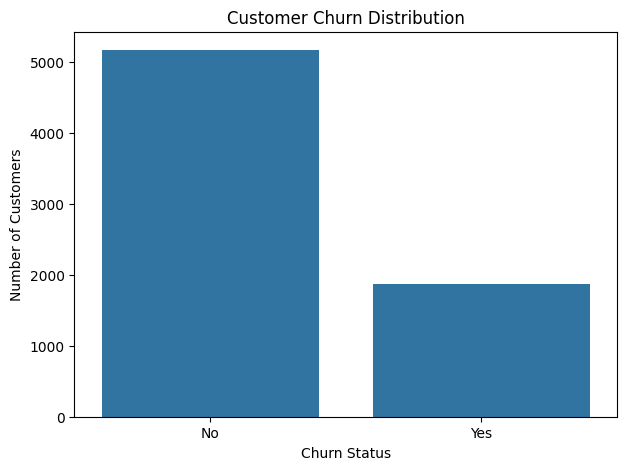

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each churn category
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reload dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Verify
print("Dataset restored successfully!")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())


Dataset restored successfully!
Shape: (7043, 21)
Missing values: 0


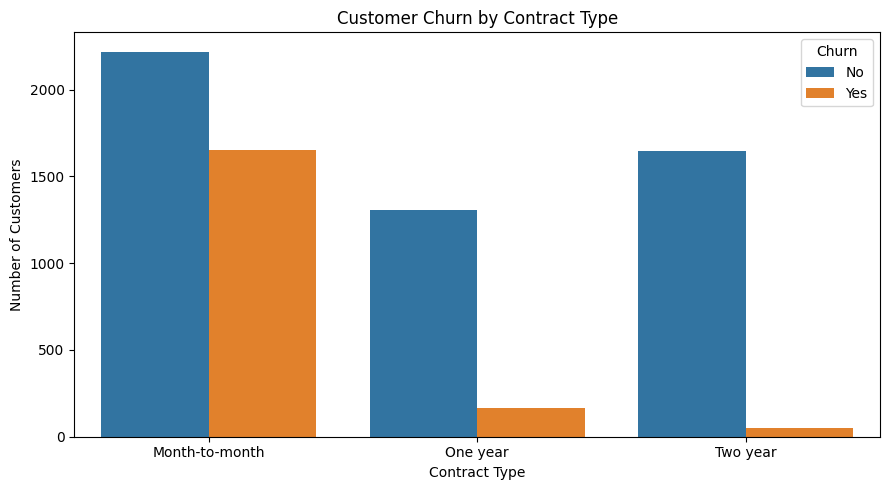

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


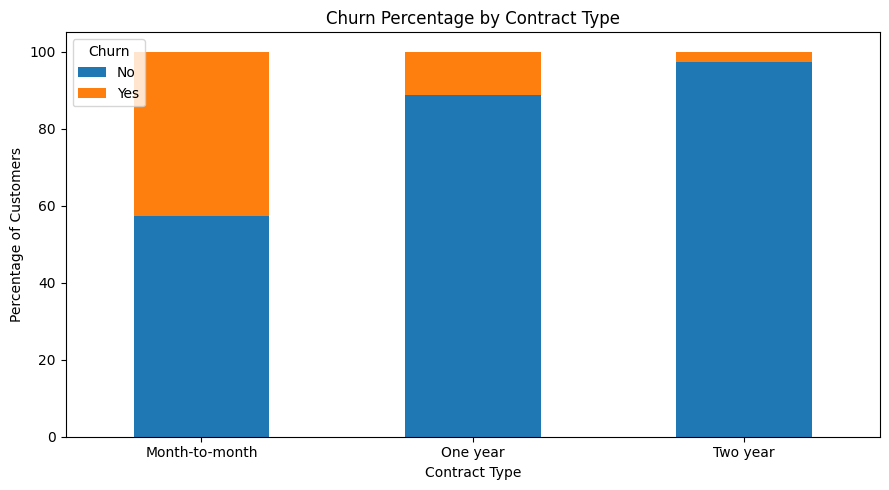

In [ ]:

# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn percentage by contract type:")
display(contract_churn.round(2))

# Visualize churn percentages
contract_churn.plot(
    kind="bar",
    figsize=(9, 5),
    stacked=True
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


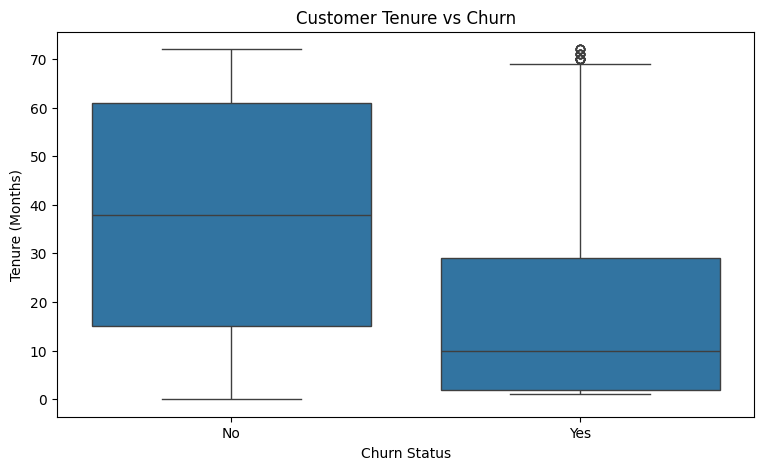

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()


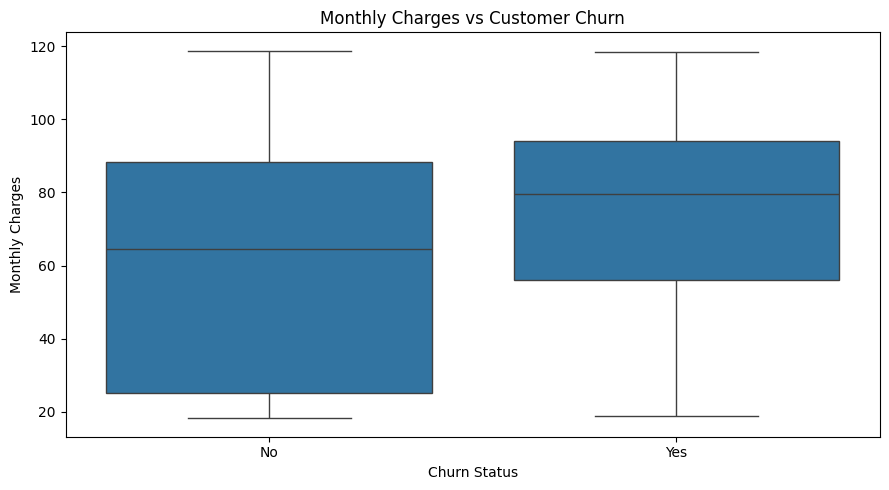

Median monthly charges by churn:
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [ ]:

# Compare monthly charges by churn status
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

# Calculate median monthly charges
print("Median monthly charges by churn:")
print(df.groupby("Churn")["MonthlyCharges"].median())


In [ ]:
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [ ]:

# Create a copy of the cleaned dataset
data = df.copy()

# Remove customer ID
data = data.drop("customerID", axis=1)

# Separate target and input features
X = data.drop("Churn", axis=1)
y = data["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (7043, 19)
Target shape: (7043,)

Input features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)


In [1]:

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


NameError: name 'Pipeline' is not defined

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("All preprocessing imports loaded successfully!")

All preprocessing imports loaded successfully!


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Data split completed successfully!")

NameError: name 'X' is not defined

In [4]:
# Separate input features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Features and target created successfully!")

NameError: name 'df' is not defined

In [5]:
print(df.shape)
print(df.head())

NameError: name 'df' is not defined

In [8]:
print(df.shape)

(7043, 21)


In [9]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 20)
Target shape: (7043,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 20)
Testing features: (1409, 20)
Training target: (5634,)
Testing target: (1409,)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

NameError: name 'preprocessor' is not defined

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical columns
numeric_features = [
    "SeniorCitizen", "tenure",
    "MonthlyCharges", "TotalCharges"
]

categorical_features = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

ValueError: could not convert string to float: ' '

In [14]:
import pandas as pd

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Replace missing values with the median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("TotalCharges cleaned successfully!")
print("Remaining missing values:", df["TotalCharges"].isna().sum())

TotalCharges cleaned successfully!
Remaining missing values: 0


In [15]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 20)
Target: (7043,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 20)
Testing: (1409, 20)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7381121362668559

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[747 288]
 [ 81 293]]


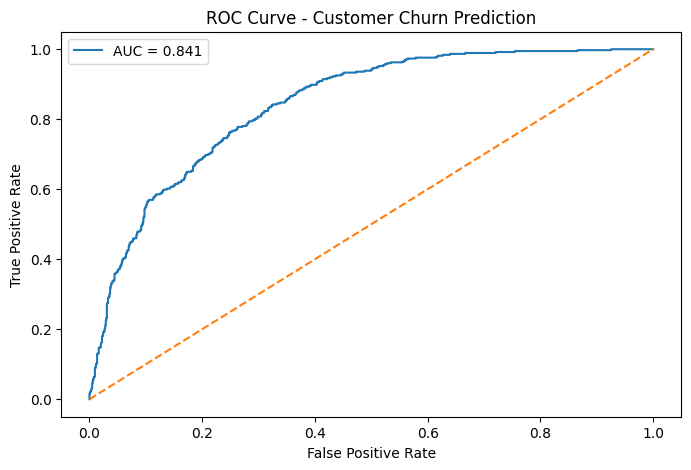

ROC-AUC Score: 0.841


In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_test_binary = y_test.map({"No": 0, "Yes": 1})

y_probability = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test_binary, y_probability
)

auc_score = roc_auc_score(y_test_binary, y_probability)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.show()

print("ROC-AUC Score:", round(auc_score, 3))

                                      Feature  Coefficient
1                                 num__tenure    -1.123595
38                     cat__Contract_Two year    -0.781255
16           cat__InternetService_Fiber optic     0.705337
2                         num__MonthlyCharges    -0.663583
36               cat__Contract_Month-to-month     0.663399
15                   cat__InternetService_DSL    -0.621009
3                           num__TotalCharges     0.457218
35                   cat__StreamingMovies_Yes     0.274978
25  cat__DeviceProtection_No internet service    -0.274569
17                    cat__InternetService_No    -0.274569
19    cat__OnlineSecurity_No internet service    -0.274569
28       cat__TechSupport_No internet service    -0.274569
31       cat__StreamingTV_No internet service    -0.274569
22      cat__OnlineBackup_No internet service    -0.274569
34   cat__StreamingMovies_No internet service    -0.274569


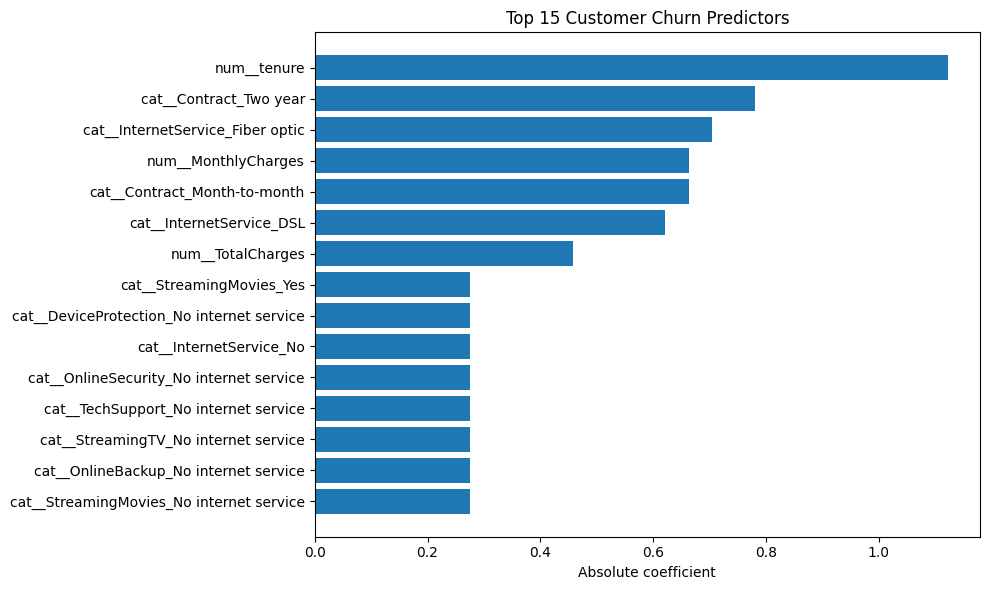

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get model coefficients
coefficients = model.named_steps["classifier"].coef_[0]

importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance["Importance"] = importance["Coefficient"].abs()

importance = importance.sort_values(
    by="Importance", ascending=False
).head(15)

print(importance[["Feature", "Coefficient"]])

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Absolute coefficient")
plt.title("Top 15 Customer Churn Predictors")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", clone(model.named_steps["preprocessor"])),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:,
    list(rf_model.classes_).index("Yes")]

# Evaluate
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Random Forest ROC-AUC:",
      roc_auc_score(
          (y_test == "Yes").astype(int),
          rf_probabilities
      ))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.7821149751596878
Random Forest ROC-AUC: 0.8216642124570513

Classification Report:
              precision    recall  f1-score   support

          No       0.82      0.89      0.86      1035
         Yes       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



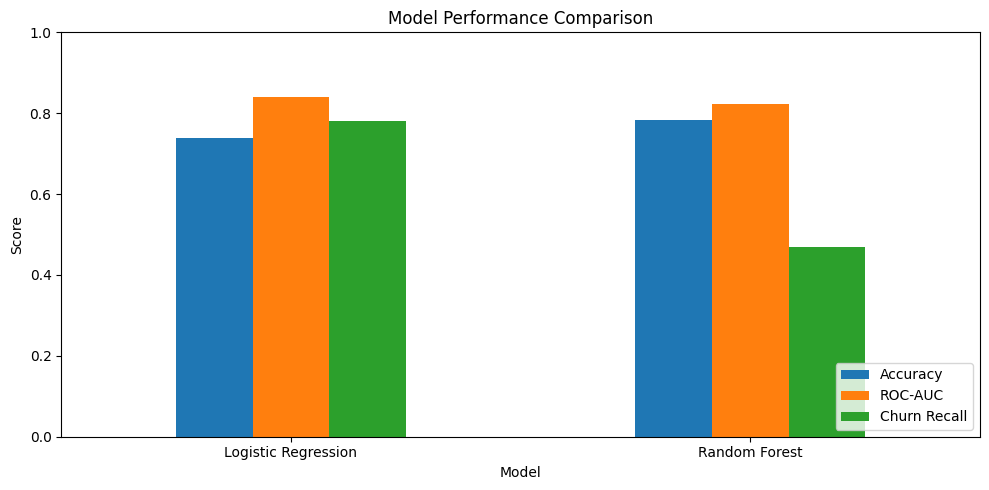

                 Model  Accuracy  ROC-AUC  Churn Recall
0  Logistic Regression    0.7381   0.8410          0.78
1        Random Forest    0.7821   0.8217          0.47


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.7381, 0.7821],
    "ROC-AUC": [0.841, 0.8217],
    "Churn Recall": [0.78, 0.47]
})

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(comparison)

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of churn (Yes)
churn_probabilities = model.predict_proba(X_test)[:,
    list(model.classes_).index("Yes")]

# Test different thresholds
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5]

results = []

for threshold in thresholds:
    predictions = (churn_probabilities >= threshold).astype(int)
    actual = (y_test == "Yes").astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(actual, predictions),
        "Recall": recall_score(actual, predictions),
        "F1-score": f1_score(actual, predictions)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))

   Threshold  Precision  Recall  F1-score
0       0.30      0.429   0.928     0.587
1       0.35      0.448   0.906     0.599
2       0.40      0.466   0.866     0.606
3       0.45      0.483   0.837     0.613
4       0.50      0.504   0.783     0.614


In [24]:
from sklearn.metrics import confusion_matrix, classification_report

best_threshold = 0.45

final_predictions = (
    churn_probabilities >= best_threshold
).astype(int)

actual = (y_test == "Yes").astype(int)

print("Selected Threshold:", best_threshold)

print("\nFinal Classification Report:")
print(classification_report(actual, final_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, final_predictions))

Selected Threshold: 0.45

Final Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.68      0.78      1035
           1       0.48      0.84      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.76      0.70      1409
weighted avg       0.80      0.72      0.74      1409


Confusion Matrix:
[[700 335]
 [ 61 313]]


In [25]:
import joblib

final_model_bundle = {
    "model": model,
    "threshold": 0.45,
    "model_name": "Logistic Regression"
}

joblib.dump(final_model_bundle, "final_churn_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [26]:
import joblib

# Load the saved model
loaded_bundle = joblib.load("final_churn_model.pkl")

loaded_model = loaded_bundle["model"]
threshold = loaded_bundle["threshold"]

# Test using one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict churn probability
probability = loaded_model.predict_proba(sample_customer)[0]
yes_index = list(loaded_model.classes_).index("Yes")

churn_probability = probability[yes_index]

# Apply selected threshold
prediction = "Yes" if churn_probability >= threshold else "No"

print("Model loaded successfully!")
print(f"Churn probability: {churn_probability:.2%}")
print("Predicted churn:", prediction)

Model loaded successfully!
Churn probability: 11.55%
Predicted churn: No


In [27]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Page configuration
st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

# Load trained model
bundle = joblib.load("final_churn_model.pkl")
model = bundle["model"]
threshold = bundle["threshold"]

st.title("📊 Customer Churn Prediction")
st.write("Predict whether a customer is likely to leave the service.")

st.divider()

st.subheader("Enter Customer Details")

with st.form("customer_form"):

    col1, col2 = st.columns(2)

    with col1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior = st.selectbox("Senior Citizen", [0, 1])
        partner = st.selectbox("Partner", ["Yes", "No"])
        dependents = st.selectbox("Dependents", ["Yes", "No"])
        tenure = st.number_input(
            "Tenure (Months)", min_value=0, max_value=72, value=12
        )
        phone = st.selectbox("Phone Service", ["Yes", "No"])
        multiple = st.selectbox(
            "Multiple Lines",
            ["Yes", "No", "No phone service"]
        )
        internet = st.selectbox(
            "Internet Service", ["DSL", "Fiber optic", "No"]
        )
        security = st.selectbox(
            "Online Security",
            ["Yes", "No", "No internet service"]
        )
        backup = st.selectbox(
            "Online Backup",
            ["Yes", "No", "No internet service"]
        )

    with col2:
        protection = st.selectbox(
            "Device Protection",
            ["Yes", "No", "No internet service"]
        )
        support = st.selectbox(
            "Tech Support",
            ["Yes", "No", "No internet service"]
        )
        tv = st.selectbox(
            "Streaming TV",
            ["Yes", "No", "No internet service"]
        )
        movies = st.selectbox(
            "Streaming Movies",
            ["Yes", "No", "No internet service"]
        )
        contract = st.selectbox(
            "Contract",
            ["Month-to-month", "One year", "Two year"]
        )
        paperless = st.selectbox(
            "Paperless Billing", ["Yes", "No"]
        )
        payment = st.selectbox(
            "Payment Method",
            [
                "Electronic check",
                "Mailed check",
                "Bank transfer (automatic)",
                "Credit card (automatic)"
            ]
        )
        monthly = st.number_input(
            "Monthly Charges",
            min_value=0.0,
            max_value=200.0,
            value=70.0
        )
        total = st.number_input(
            "Total Charges",
            min_value=0.0,
            value=840.0
        )

    submitted = st.form_submit_button("Predict Customer Churn")

if submitted:

    customer = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": senior,
        "Partner": partner,
        "Dependents": dependents,
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": multiple,
        "InternetService": internet,
        "OnlineSecurity": security,
        "OnlineBackup": backup,
        "DeviceProtection": protection,
        "TechSupport": support,
        "StreamingTV": tv,
        "StreamingMovies": movies,
        "Contract": contract,
        "PaperlessBilling": paperless,
        "PaymentMethod": payment,
        "MonthlyCharges": monthly,
        "TotalCharges": total
    }])

    probabilities = model.predict_proba(customer)[0]
    yes_index = list(model.classes_).index("Yes")
    churn_probability = probabilities[yes_index]

    prediction = (
        "Yes" if churn_probability >= threshold else "No"
    )

    st.divider()
    st.subheader("Prediction Result")

    st.metric(
        "Churn Probability",
        f"{churn_probability:.2%}"
    )

    if prediction == "Yes":
        st.error("⚠️ This customer is likely to churn.")
    else:
        st.success("✅ This customer is unlikely to churn.")

    st.caption(f"Decision threshold: {threshold:.0%}")

Writing app.py


In [29]:
%pip install -q streamlit

In [30]:
!streamlit run app.py &>/content/streamlit.log &
print("Streamlit server started!")

Streamlit server started!


In [31]:
!tail -20 /content/streamlit.log



2026-11-01 14:11:07.600 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.171.63.193:8501



In [32]:
%pip install -q pyngrok

from pyngrok import ngrok
from getpass import getpass

ngrok.set_auth_token(getpass("Enter your ngrok auth token: "))

public_url = ngrok.connect(8501)
print("Your Customer Churn Prediction App:", public_url)

Enter your ngrok auth token: ··········
Your Customer Churn Prediction App: NgrokTunnel: "https://garden-limit-unwary.ngrok-free.dev" -> "http://localhost:8501"


In [33]:
from google.colab import files

files.download("app.py")
files.download("final_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!ls -lh

total 4.0K
drwxr-xr-x 1 root root 4.0K Oct 29 15:20 sample_data
